# 12B 최종 보고 — KODEX 200 CUSUM 을 실제 시장 위에 겹쳐 보면

**R2H 12B (T22)** · 069500 KODEX 200 · 2020-01-02 ~ 2025-12-30 · 계약 `12B-lock-1` · 브랜치 `research/12b_k200_cusum_volatility_alignment`

12번의 463개 일별 CUSUM 정책(681,999행)을 종가·수익률·연환산변동성과 같은 날짜축에 전수 정렬하고, 한 변수씩 바꾼 정책을 시장 경로 위에 겹쳐 비교했다.
요청한 **X1 자기정규화 Page 의 실데이터 적용** 을 맨 앞에 둔다.

> 이 노트북은 결과 제시용이다. 계산·게이트는 연구 노트북 `12B_KODEX200_CUSUM_시장변수_연환산변동성_정렬비교.ipynb` 가 담당하고, 여기서는 그 동결 결과만 읽는다.
> 관측 귀무 모형이 맞지 않으므로(`NULL_MODEL_INVALID`) 모든 경보·임계값은 서술용 참조다.

### 한눈에 보기

| 질문 | 답 |
|---|---|
| X1 은 실데이터에서? | 2020-09-21 부터 값이 있어 COVID 를 못 본다. 2021–2025 상방 경보 0회, 하방 4회(COVID 뒤 정상화기). 2019 잔차로 시작한 X1w(보정 없는 참조)는 2020-03-18 — 원래 Page 보다 3거래일 빠르다 |
| 새 발견 | SVR 예측분산이 2020-02-25 ~ 08-21 의 32일 동안 1.127 에 **상수 고정** (커널 소실, 기계적 확인). 2020 경보와 동시 발생 (인과 미확인) |
| 급증 / 높은 수준 / 감소 | 이동 CoS / Page 상방(표류 섞임) / CoS·Page 하방·X1 하방 |
| 창 길이 · 초기화 | 창은 기억 길이를 바꾼다 (w20–w60 ρ 0.07). CoS 초기화는 관측 공백만 더한다 |
| 중복성 | 463 정책 → 값 군집 73개. 117개 CoS 군집, 107개 Page 하방 군집은 사실상 한 신호 |
| AE 인계 | CoS 4개 창 · 원수익률 CoS · Page 하방 · X1(검증 후) · 예측분산 + 상수 고정 표시 · 마스크. 경보·p값은 넘기지 않는다 |

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t22_k200_overlay_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import contextlib  # 단계 출력 가두기
import hashlib  # 파일 지문
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import importlib.util  # 단계 스크립트 불러오기
import io  # 출력 버퍼
import json  # 설정·캡션
import platform  # Python 버전
import time  # 단계 소요 시간

import matplotlib  # 그림 백엔드
matplotlib.use("Agg")  # 화면 없이 파일로 저장
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, Markdown, display  # 표·그림·문단 출력
import matplotlib.pyplot as plt  # 그림 기본 설정
from matplotlib import font_manager  # 한글 글꼴 등록

FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = font_manager.FontProperties(fname=str(FONT_FILE)).get_name()  # 한글 글꼴 사용
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지

# 12번과 같은 고정 환경 (user-site 차단 포함).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2", "scikit-learn": "1.9.1"}  # 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), **{k: metadata.version(k) for k in ("numpy", "pandas", "scipy", "matplotlib", "scikit-learn")}}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패
assert ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
pd.set_option("display.width", 220)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화
pd.set_option("display.max_rows", 60)  # 행 생략 완화

from r2h.k200_overlay import figures as G  # 12B 그림 (대표 쌍·라벨)

assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
BASE = ROOT / "research/k200_cusum_overlay_12b"  # 12B 산출물 폴더
RES = BASE / "results"  # 결과표
FIGDIR = BASE / "figures"  # 그림 (PNG 320dpi + SVG)
OUT = ROOT / "outputs/t22"  # 일별 장형 Parquet (Git 제외)


def sha(p):  # 파일 SHA256
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()  # 바이트 단위 지문


def preview(path, width=1100):  # 노트북 용량을 줄이는 축소 미리보기 (원본은 figures/)
    from PIL import Image as PILImage  # 이미지 축소
    im = PILImage.open(path)  # 320dpi 원본
    im.thumbnail((width, width * 3))  # 가로 1100px 이하로 축소
    buf = io.BytesIO()  # 출력 버퍼
    im.save(buf, format="PNG", optimize=True)  # PNG 로 다시 저장
    return buf.getvalue()  # 바이트 반환


# 계약 동결 지문: 국면·이벤트 정의는 계산 전에 커밋한 그대로여야 한다.
FREEZE = dict(reversed(line.split(maxsplit=1)) for line in (BASE / "CONTRACT_FREEZE_SHA256.txt").read_text().splitlines())  # 경로 → 해시
assert all(sha(ROOT / p) == h for p, h in FREEZE.items()), "12B-lock-1 계약 파일 변경"  # 동결본과 같아야 한다
# 12번 기준 커밋 c8998a6 의 추적 파일 915개 지문 — 실행 전후 모두 같아야 한다 (G0).
PROT = [line.split(maxsplit=1) for line in (BASE / "evidence/PROTECTED_12_SHA256.txt").read_text().splitlines()]  # (해시, 경로)
bad = [p for h, p in PROT if sha(ROOT / p) != h]  # 바뀐 보호 파일
assert not bad, f"보호 파일 변경: {bad[:5]}"  # 12번 산출물은 읽기만
INPUTS = [line.split(maxsplit=1) for line in (BASE / "evidence/INPUT_SHA256.txt").read_text().splitlines()]  # 동결 입력 (Feature Store·귀무표·원자료)
bad_in = [p for h, p in INPUTS if sha(ROOT / p) != h]  # 바뀐 입력
assert not bad_in, f"동결 입력 변경: {bad_in}"  # 12번 Feature Store 를 그대로 써야 한다
print("작업트리:", ROOT, "| 12번 보호", len(PROT), "개 · 입력", len(INPUTS), "개 불변 | 환경", ACTUAL_ENV)  # 검증 요약

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1019/R2H_K200_CUSUM_12 | 12번 보호 915 개 · 입력 14 개 불변 | 환경 {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1'}


## 1. 검증 상태

In [2]:
# 계산은 하지 않는다: 연구 노트북·스크립트가 만든 동결 결과표·그림·릴리스 기록만 읽는다.
T = {p.name: pd.read_csv(p) for p in sorted(RES.glob("*.csv*"))}  # 결과표 전부 (gzip 포함)
CAP = json.loads((RES / "figure_captions.json").read_text(encoding="utf-8"))  # 그림 캡션 수치
MAN = json.loads((BASE / "RELEASE_MANIFEST.json").read_text(encoding="utf-8"))  # 릴리스 기록
X1C = json.loads((BASE / "evidence/x1_checks.json").read_text(encoding="utf-8"))  # X1 원장 재계산·fit 0 검사
G6 = pd.read_csv(BASE / "evidence/g6_figure_ledger_check.csv")  # 그림–원장 일치 기록
REC = json.loads((BASE / "evidence/execution_record.json").read_text(encoding="utf-8"))  # 연구 노트북 실행 기록
gates = pd.DataFrame([  # 게이트 요약표
    ("G0 12번 보호", f"{MAN['G0_protected_12_files']}개 중 변경 {len(MAN['G0_changed'])}"),  # 기존 연구 불변
    ("G1–G3·G7 정렬", f"{int(T['policy_market_alignment_audit.csv']['pass'].astype(str).eq('True').sum())}/{len(T['policy_market_alignment_audit.csv'])} 통과"),  # 날짜·전수·시장변수·결측
    ("G4 OFAT (구조 판정)", f"불일치 {int((~T['ofat_pair_comparison.csv'].ofat_consistent_structural.astype(bool)).sum())} / {len(T['ofat_pair_comparison.csv'])}쌍"),  # 한 변수 변경 확인
    ("G6 그림–원장", f"{int(G6['equal'].sum())}/{len(G6)} 일치"),  # 그린 값 = 원장 값
    ("X1 원장 재계산", f"{sum(v for k, v in X1C.items() if k.endswith('_equal'))}/{sum(1 for k in X1C if k.endswith('_equal'))} 일치"),  # 재적합 없이 동일
    ("G10 연구 노트북", f"{REC['status']} · {REC['seconds']}초"),  # 새 커널 실행
    ("재현성", str(MAN["reproducibility_notebook_vs_script"])),  # 노트북 경로 = 스크립트 경로
    ("단위 시험", MAN["tests"]),  # pytest 결과
], columns=["게이트", "결과"])  # 표 열 이름
display(gates)  # 표 출력

,게이트,결과
0,G0 12번 보호,915개 중 변경 0
1,G1–G3·G7 정렬,32/32 통과
2,G4 OFAT (구조 판정),불일치 0 / 462쌍
3,G6 그림–원장,37/37 일치
4,X1 원장 재계산,14/14 일치
5,G10 연구 노트북,PASS · 151.58초
6,재현성,BYTE_IDENTICAL
7,단위 시험,14 passed in 1.11s


## 2. X1 자기정규화 Page — 실데이터 적용 (요청 사항)

X1 은 12번이 저장한 B1 잔차 e = r/√v^ 를 과거 [t−252, t−61] 의 평균 e² 로 한 번 더 나눈 값이다. **재적합이 필요 없고**, 다시 계산한 상태·경보가 원장과 비트 단위로 같다.

- **2020 이 빈다.** 기준에 유효일 120일이 필요해 값이 2020-09-21 부터 나온다.
- **상방 경보 0회 (2021–2025).** 사건 구간 중 상태/임계값 최대 0.46 (2024-08).
- **하방 4회 (2020-12-03 ~ 2021-07-01).** COVID 기간의 큰 e² 가 기준창에 남아 이후 잔차가 상대적으로 작아 보인 정상화기다.
- **X1w (탐색).** 2019 fit 0 의 표본내 잔차로 기준을 채우면 2020-03-18 에 처음 임계값을 넘는다 (원래 Page 상방 03-23). 임계값을 따로 보정하지 않아 참조로만 쓴다.

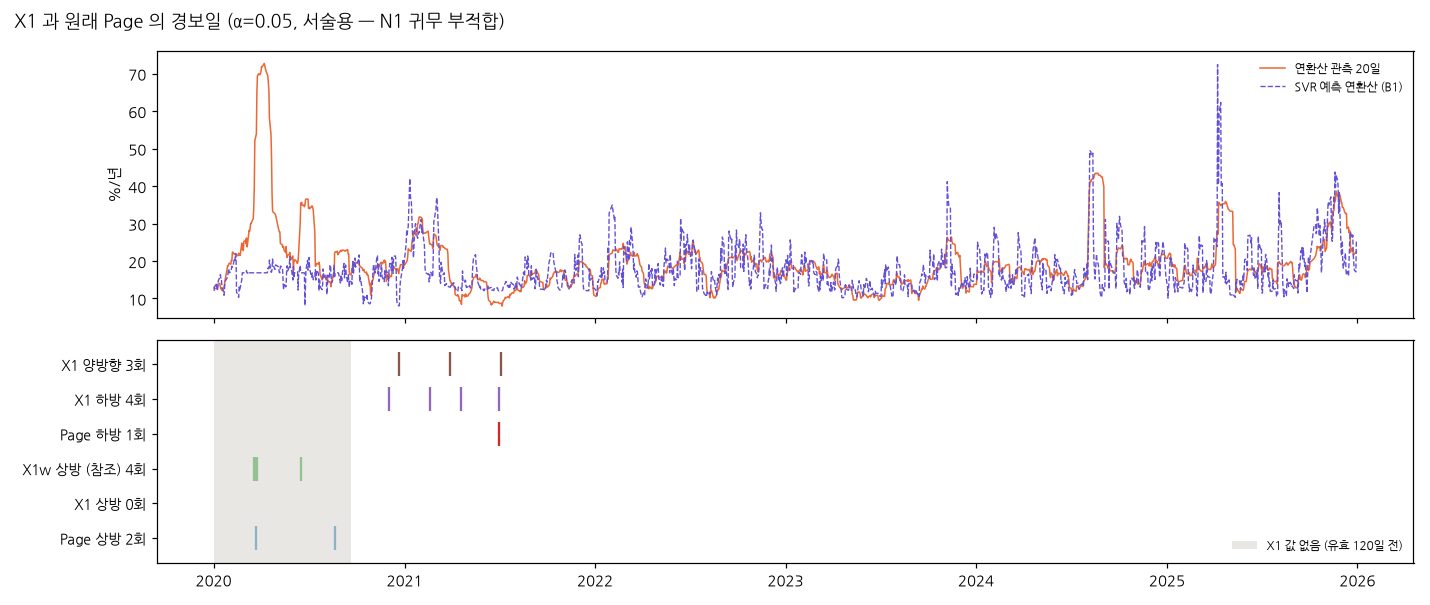

In [3]:
# 실시간 그림: X1·원래 Page 의 α=0.05 경보일과 연환산 20일 변동성을 한 축에 (결과표 x1_real_daily.csv 에서 직접 그린다)
x = T["x1_real_daily.csv"].assign(date=lambda d: pd.to_datetime(d["date"]))  # X1 일별 해부표
fig_, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})  # 변동성·경보 두 패널
ax[0].plot(x["date"], x["annualized_vol_20"], color="#eb6834", lw=1, label="연환산 관측 20일")  # 관측 변동성
ax[0].plot(x["date"], np.sqrt(252 * x["predicted_variance_B1"]), color="#6250d6", lw=0.9, ls="--", label="SVR 예측 연환산 (B1)")  # 예측 변동성
ax[0].set_ylabel("%/년")  # 단위
ax[0].legend(fontsize=8, frameon=False)  # 범례
rows = [("E3_up_alarm_a05", "Page 상방"), ("X1_up_alarm_a05", "X1 상방"), ("X1w_up_alarm_a05_REFERENCE", "X1w 상방 (참조)"), ("E3_down_alarm_a05", "Page 하방"), ("X1_down_alarm_a05", "X1 하방"), ("X1_two_alarm_a05", "X1 양방향")]  # 경보 계열
for k, (c, lab) in enumerate(rows):  # 계열마다
    d = x.loc[x[c].astype(bool), "date"]  # 경보일
    ax[1].scatter(d, np.full(len(d), k), marker="|", s=250, color=f"C{k}")  # 세로 눈금으로 표시
ax[1].axvspan(x["date"].iloc[0], x.loc[x["m_hat_X1"].notna(), "date"].iloc[0], color="#d9d8d2", alpha=0.6, lw=0, label="X1 값 없음 (유효 120일 전)")  # X1 결측 구간
ax[1].set_yticks(range(len(rows)), [f"{lab} {int(x[c].astype(bool).sum())}회" for c, lab in rows], fontsize=9)  # 계열 이름·경보 수를 눈금 라벨로
ax[1].set_ylim(-0.7, len(rows) - 0.3)  # 위아래 여유
ax[1].legend(fontsize=8, frameon=False, loc="lower right")  # 범례
fig_.suptitle("X1 과 원래 Page 의 경보일 (α=0.05, 서술용 — N1 귀무 부적합)", x=0.01, ha="left", fontsize=12)  # 제목
plt.tight_layout()  # 여백 정리
buf = io.BytesIO()  # 그림 버퍼
fig_.savefig(buf, format="png", dpi=110)  # 노트북용 해상도
plt.close(fig_)  # 메모리 해제
display(Image(data=buf.getvalue()))  # 표시

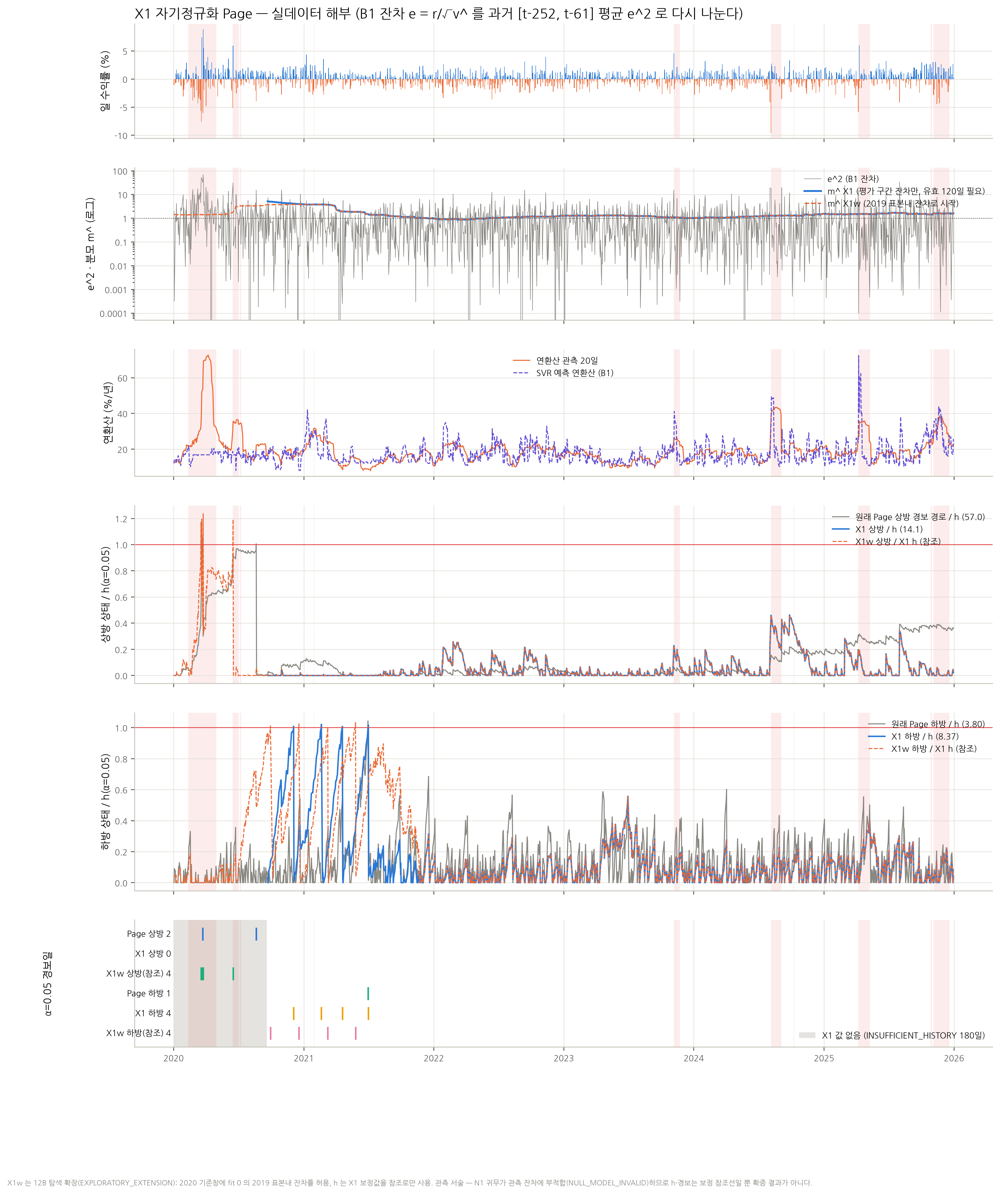

In [4]:
display(Image(data=preview(FIGDIR / "G02_X1_자기정규화Page_실데이터.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

### 왜 2024-08-05 −9.63% 에도 울리지 않았나

그날 SVR 예측분산 v^ 가 이미 5.01 이라 잔차가 −4.30 에 그쳤다. CUSUM 은 원수익률이 아니라 **SVR 이 놓친 몫**만 본다. 2020 에는 반대로 v^ 가 1.127 에 묶여 있어 잔차가 원수익률에 가까웠다.

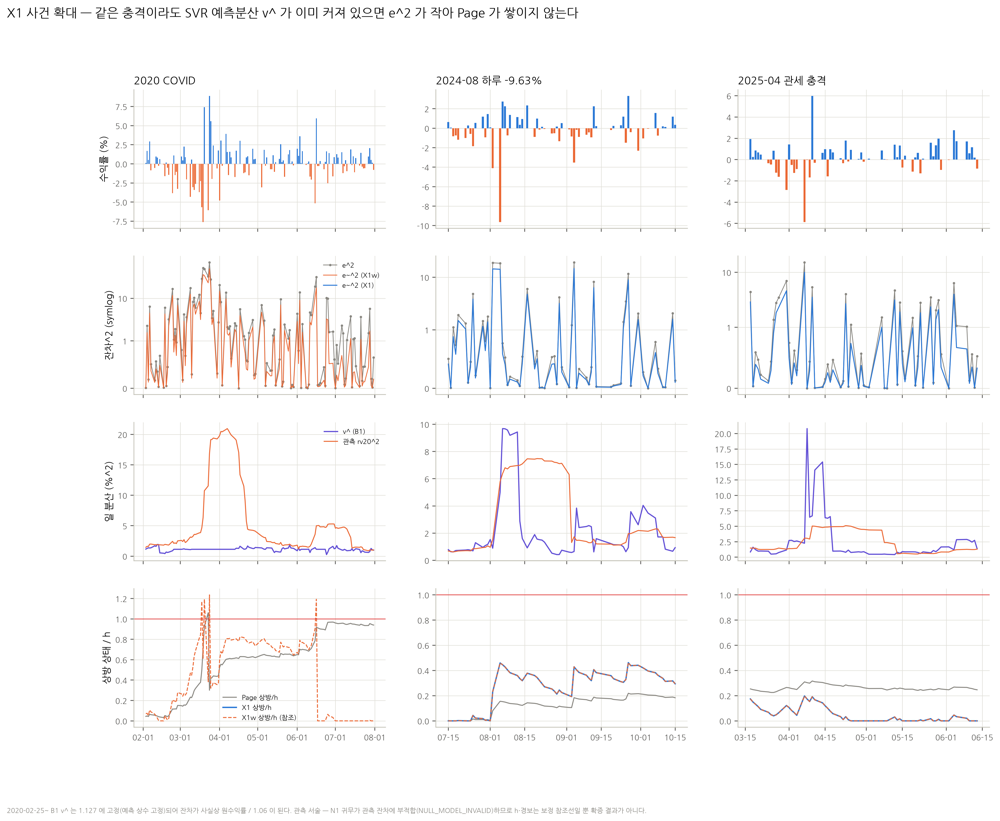

In [5]:
display(Image(data=preview(FIGDIR / "G03_X1_사건확대.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

### X1 은 원래 Page 와 다른 정보인가

공통일 순위 상관이 −0.25 다. 원래 Page 상방은 잔차 척도가 1 보다 크면(평균 e² > 1.39) 상태가 계속 쌓이는 표류가 있어 변동성 **수준**과 상관 0.58 을 보이는데, X1 은 이를 지워 0.26 이 된다.

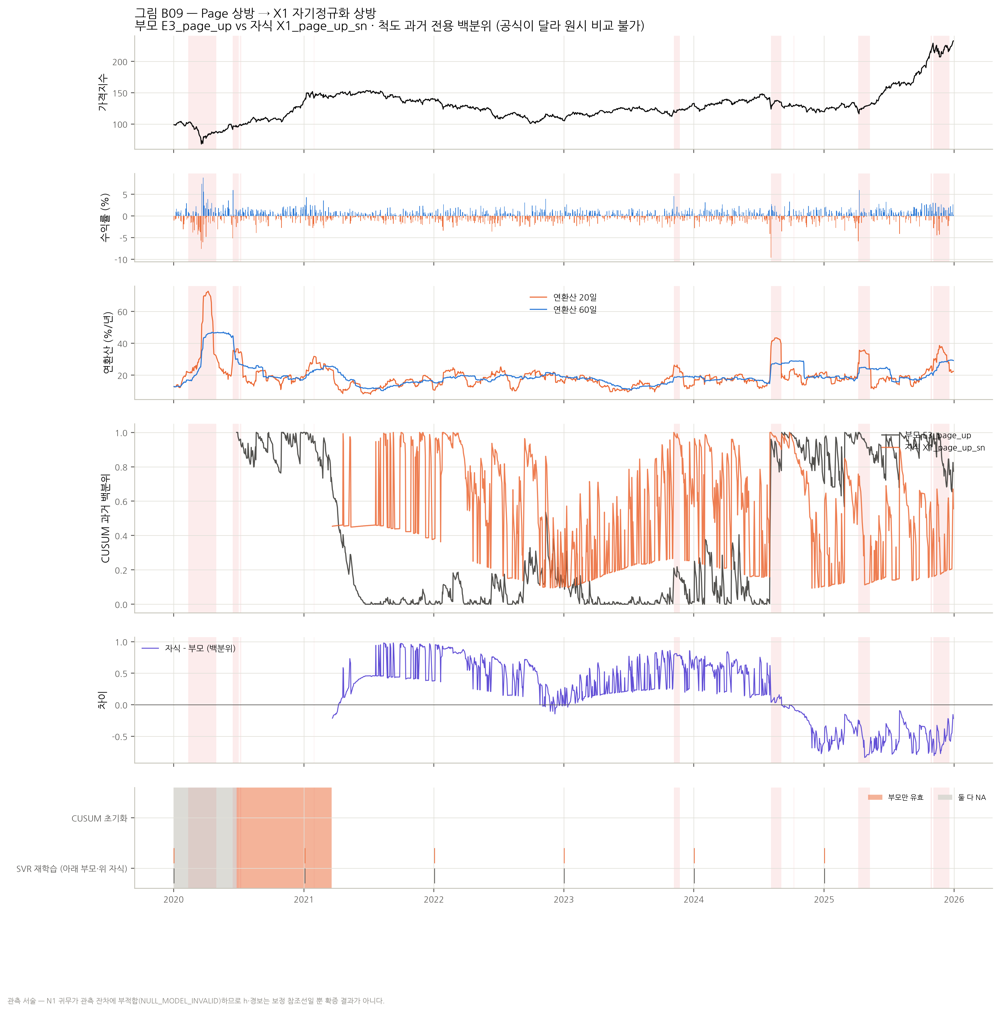

In [6]:
display(Image(data=preview(FIGDIR / "G05_09_부모자식_E3_page_up_vs_X1_page_up_sn.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

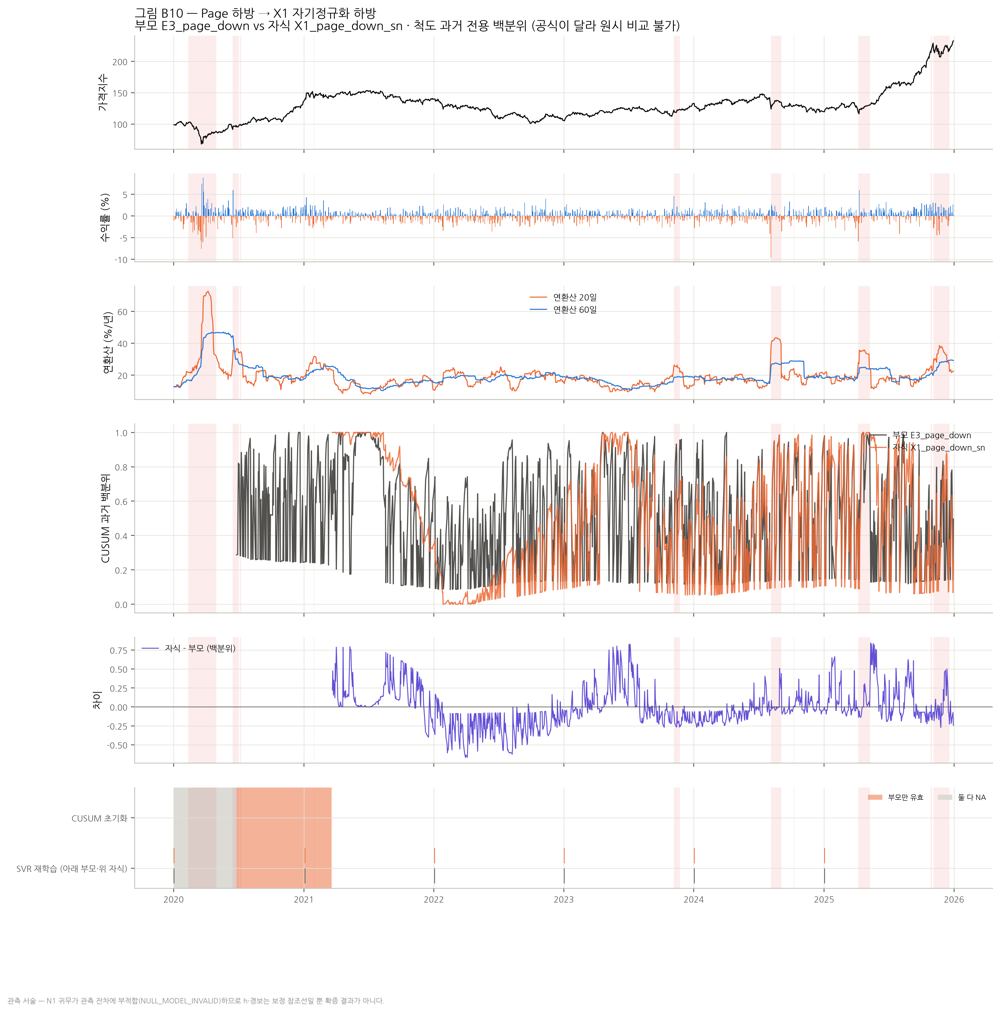

In [7]:
display(Image(data=preview(FIGDIR / "G05_10_부모자식_E3_page_down_vs_X1_page_down_sn.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

In [8]:
# 사건별 상태/임계값 최대 — 자유 상태(free, 표류 포함)와 경보 경로(path) 분리
display(T['x1_event_table.csv'].query('event_set=="A_t20"')[['interval_id','shock_type','period','E3_up_free_max_over_h','E3_up_path_max_over_h','X1_up_path_max_over_h','X1w_up_path_max_over_h','X1_down_path_max_over_h','E3_up_first_alarm_a05','X1w_up_first_alarm_a05']].round(2))  # 표 출력

,interval_id,shock_type,period,E3_up_free_max_over_h,E3_up_path_max_over_h,X1_up_path_max_over_h,X1w_up_path_max_over_h,X1_down_path_max_over_h,E3_up_first_alarm_a05,X1w_up_first_alarm_a05
0,069500_q20_001,누적형,PILOT,1.72,1.06,NaN,1.24,NaN,2020-03-23,2020-03-18
1,069500_q20_002,단일 충격형,PILOT,2.03,0.97,NaN,1.19,NaN,NaN,2020-06-16
2,069500_q20_003,단일 충격형,PILOT,2.02,0.96,NaN,0.01,NaN,NaN,NaN
3,069500_q20_004,단일 충격형,PILOT,2.02,0.96,NaN,0.01,NaN,NaN,NaN
4,069500_q20_005,누적형,PRIMARY,2.14,0.11,0.01,0.01,1.02,NaN,NaN
5,069500_q20_006,단일 충격형,PRIMARY,1.31,0.06,0.23,0.23,0.20,NaN,NaN
6,069500_q20_007,단일 충격형,PRIMARY,1.39,0.22,0.46,0.46,0.23,NaN,NaN
7,069500_q20_008,누적형,PRIMARY,1.37,0.20,0.38,0.38,0.22,NaN,NaN
8,069500_q20_009,단일 충격형,PRIMARY,1.48,0.32,0.20,0.20,0.40,NaN,NaN
9,069500_q20_010,누적형,PRIMARY,1.56,0.39,0.06,0.06,0.14,NaN,NaN


## 3. 새 발견 — SVR 예측분산 상수 고정 (커널 소실)

같은 적합 안에서 예측분산이 소수점 9자리까지 같은 값으로 5일 이상 반복되는 날을 찾았다. B1 은 2020-02-25 부터 1.127 에 32일 묶였고, 그동안 관측 20일 분산은 2 에서 20 까지 올랐다.
입력이 2019 학습 범위를 벗어나 RBF 커널 기여가 0 이 되면 절편 상수만 남는다 — fit 0 에 아주 먼 입력을 넣으면 정확히 1.1272266 이 나온다. 같은 적합의 2020 최대 v^ 는 1.92 라 '상한' 이 아니다.
B1 의 2020 경보 43일 중 13일이 고정일 당일이다. 함께 일어났을 뿐이며, 고정일 v^ 를 바꿔 넣는 반사실 계산 전까지 원인으로 말하지 않는다.

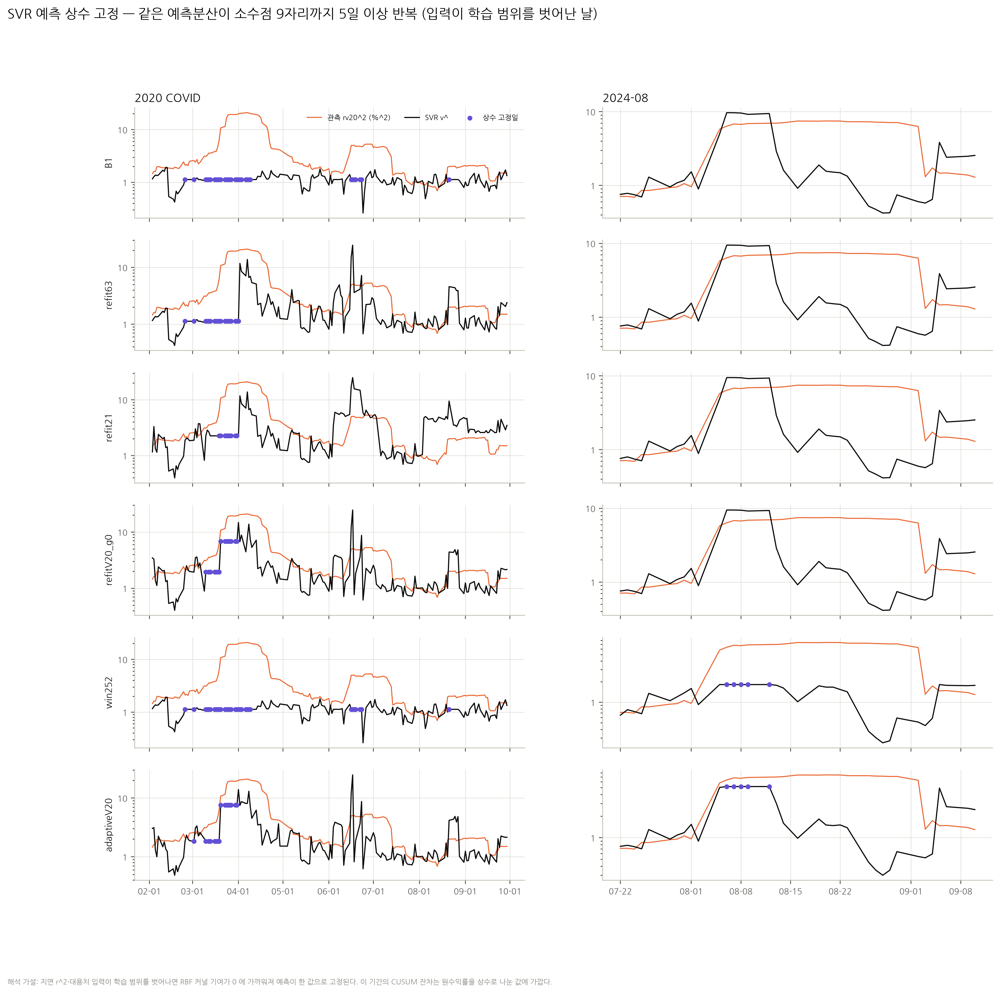

In [9]:
display(Image(data=preview(FIGDIR / "G04_SVR_예측상수고정.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

In [10]:
# 정책·적합별 상수 고정 구간 (열 이름 forecast_ceiling 은 호환용, D-11)
display(T['svr_forecast_ceiling_summary.csv'].round(3))  # 표 출력

,policy_id,model_fit_id,ceiling_value,days,first,last,mean_abs_return,mean_rv20
0,B1,0,1.127,32,2020-02-25,2020-08-21,2.860,3.066
1,adaptiveV20,1,1.834,8,2020-03-02,2020-03-19,3.348,1.968
2,adaptiveV20,2,7.571,8,2020-03-20,2020-03-31,4.329,4.093
3,adaptiveV20,11,5.153,5,2024-08-06,2024-08-12,1.647,2.598
4,refit21,2,2.254,9,2020-03-19,2020-03-31,4.693,3.918
5,refit63,0,1.127,19,2020-02-25,2020-04-01,3.704,2.958
6,refitV20_g0,1,1.938,7,2020-03-10,2020-03-19,3.689,2.019
7,refitV20_g0,2,6.840,8,2020-03-20,2020-03-31,4.329,4.093
8,refitV20_g20,1,2.268,18,2020-03-13,2020-04-08,3.755,3.658
9,refitV20_g60,0,1.127,25,2020-02-25,2020-04-09,3.287,3.337


In [11]:
# B1 경보일과 상수 고정일의 겹침 (동시 발생 기술)
display(T['b1_alarm_constant_overlap.csv'])  # 표 출력

,alarm_days_a05,alarm_on_constant_day,alarm_within_60d_after_constant_day,constant_days,constant_span_first,constant_span_last,label
0,43,13,43,32,2020-02-25,2020-08-21,CO_OCCURRENCE_NOT_CAUSAL


## 4. 6년 시장 경로 위의 CUSUM

대표 12정책의 **과거 전용 백분위**(t 이전 252일 자기 분포 안 위치, 0–1)를 띠로 쌓았다. 회색 = 값 없음(NA), 붉은 음영 = 11번 급변 구간(CUSUM 과 독립 정의).
아래 띠는 변화점·연초 초기화·재학습·예측 상수 고정, 맨 아래는 과거 전용 연환산 국면이다.

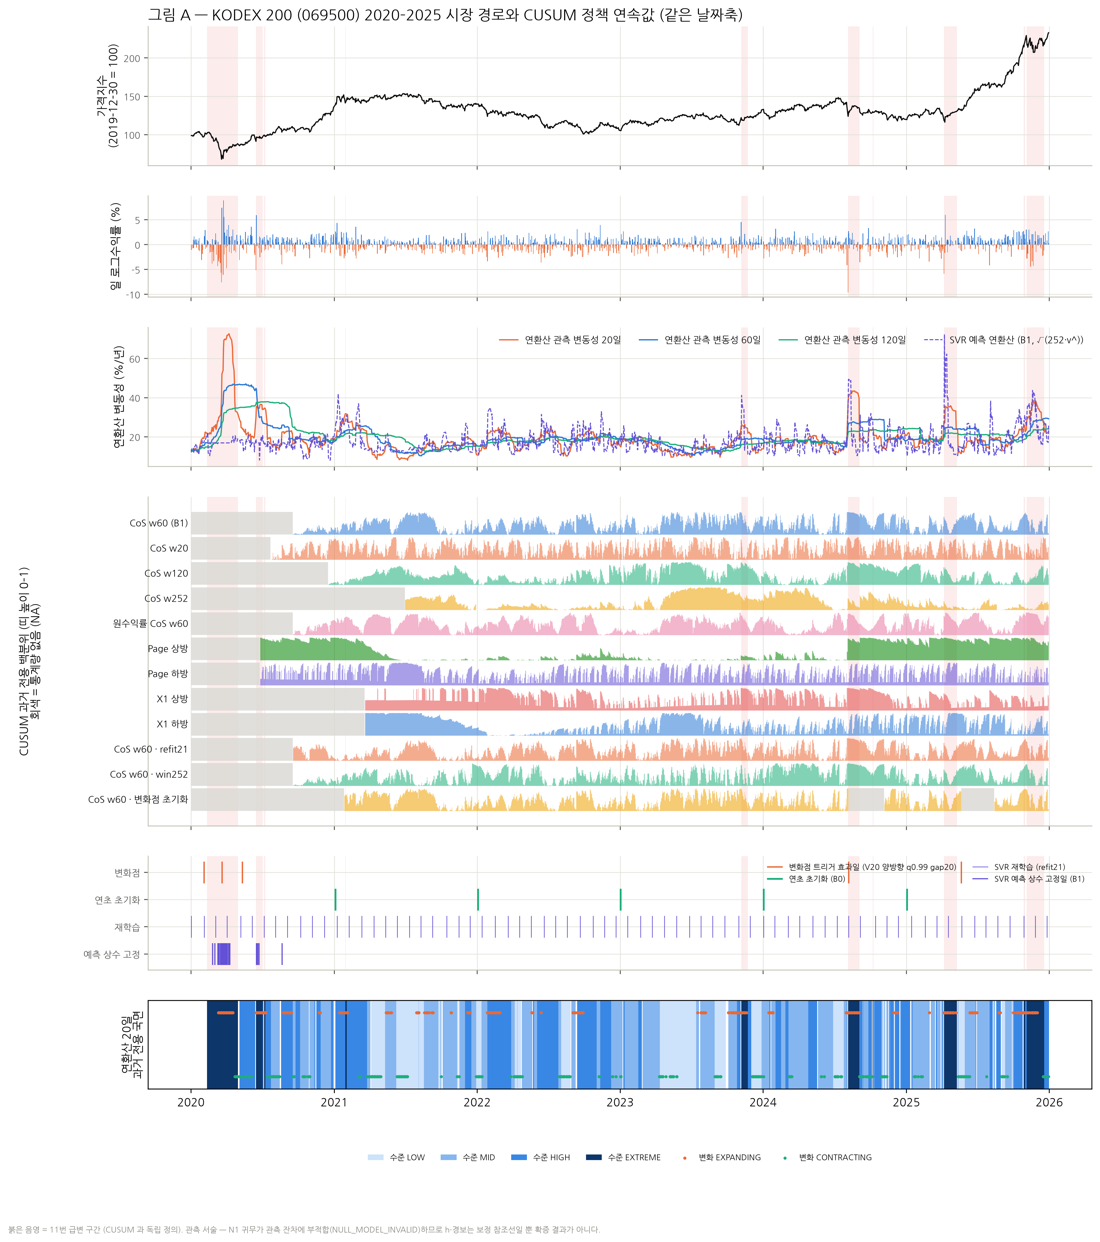

In [12]:
display(Image(data=preview(FIGDIR / "G01_6년_시장_CUSUM_정렬지도.png", width=1100)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

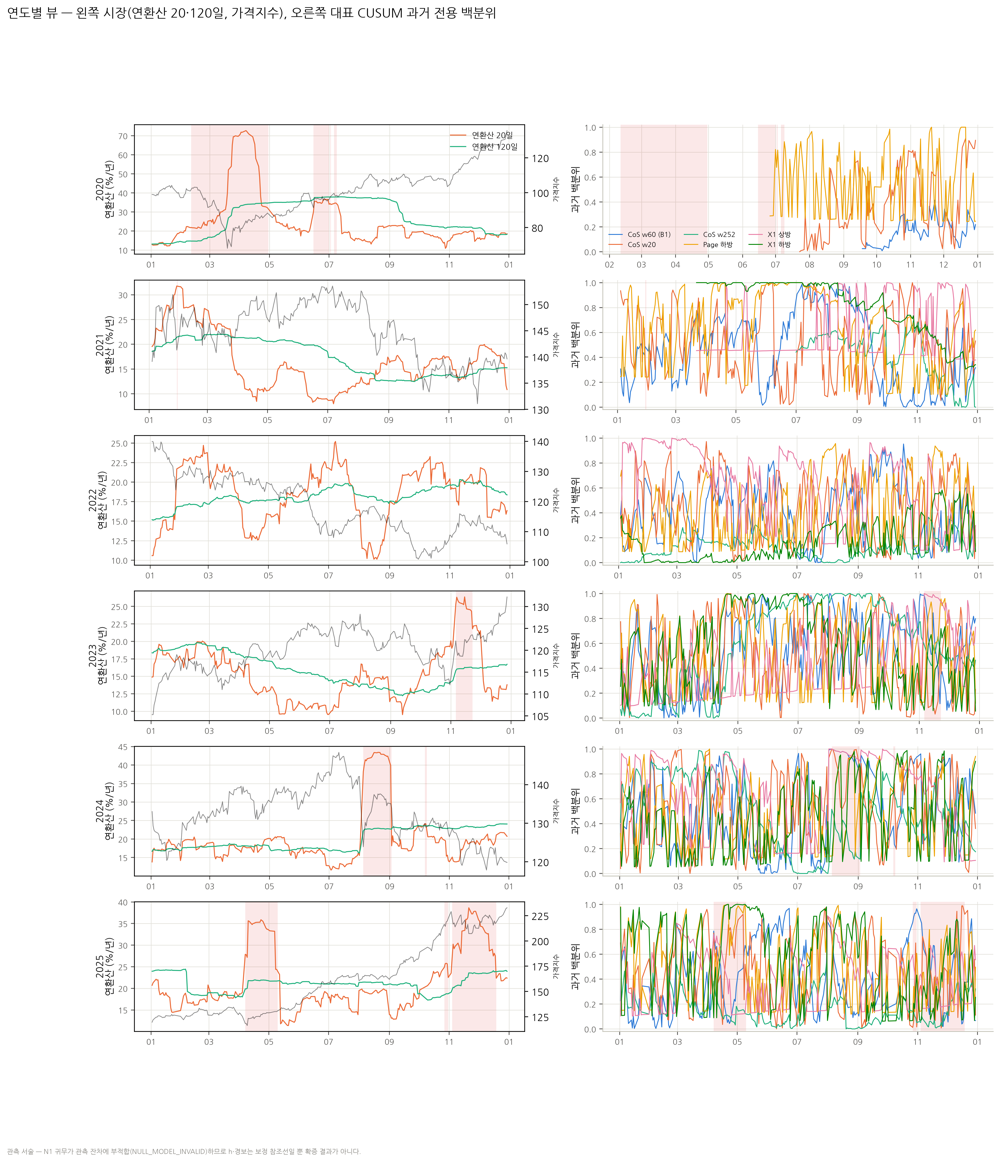

In [13]:
display(Image(data=preview(FIGDIR / "G06_연도별_시장_CUSUM.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

## 5. 한 변수만 바꾸면 — 부모–자식 중첩

- **창 길이**: 날짜별 순위가 크게 바뀐다 (공통일 ρ: w20 0.07 · w120 0.38 · w252 0.35). 긴 창은 충격이 창에서 빠질 때(d + w)까지 기억한다 — w252 경보 159일·NA 192일 추가.
- **변화점 초기화 (CoS)**: 공통 유효일에서 값이 부모와 같다 (ρ = 1.00). 달라지는 것은 초기화 직후 NA 뿐 — 관측 공백 추가다.
- **SVR 학습·재학습**: 잔차 척도를 바꿔 같은 날 값이 달라진다 (win252 ρ 0.67, refit21 0.89).

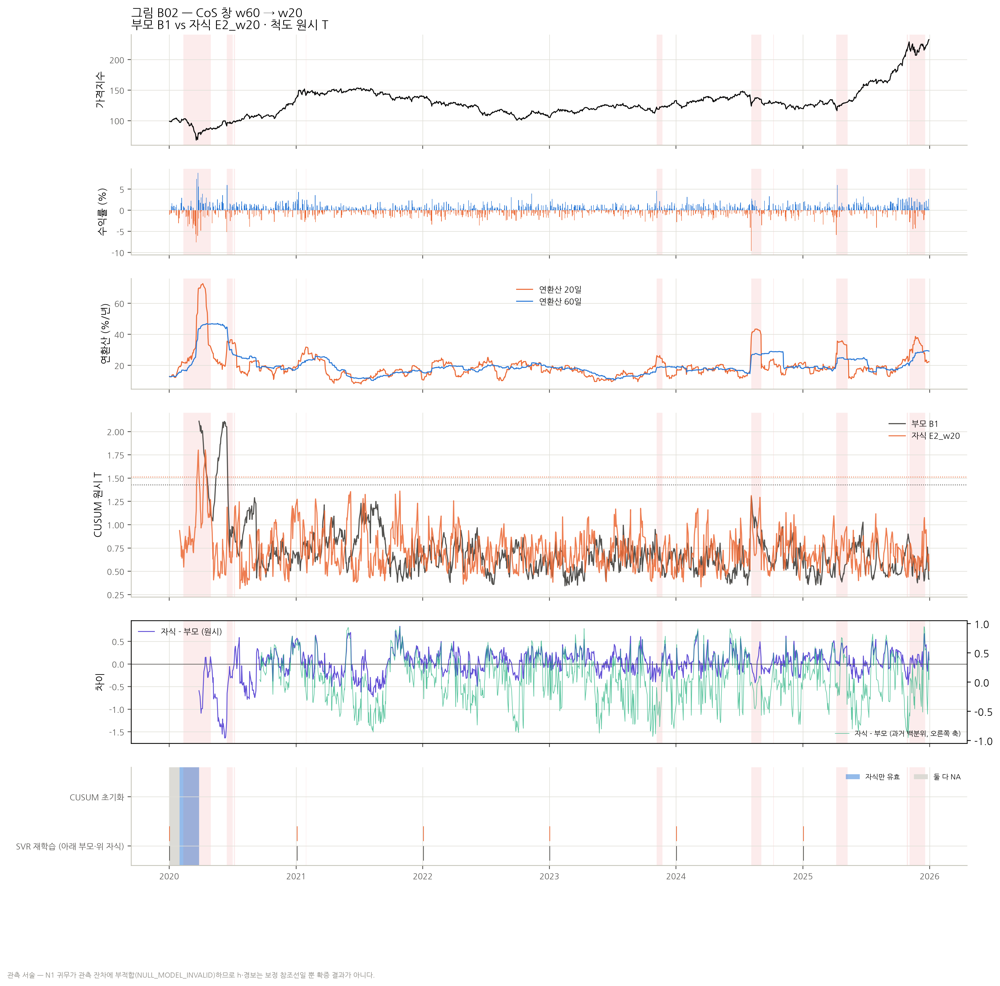

In [14]:
display(Image(data=preview(FIGDIR / "G05_02_부모자식_B1_vs_E2_w20.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

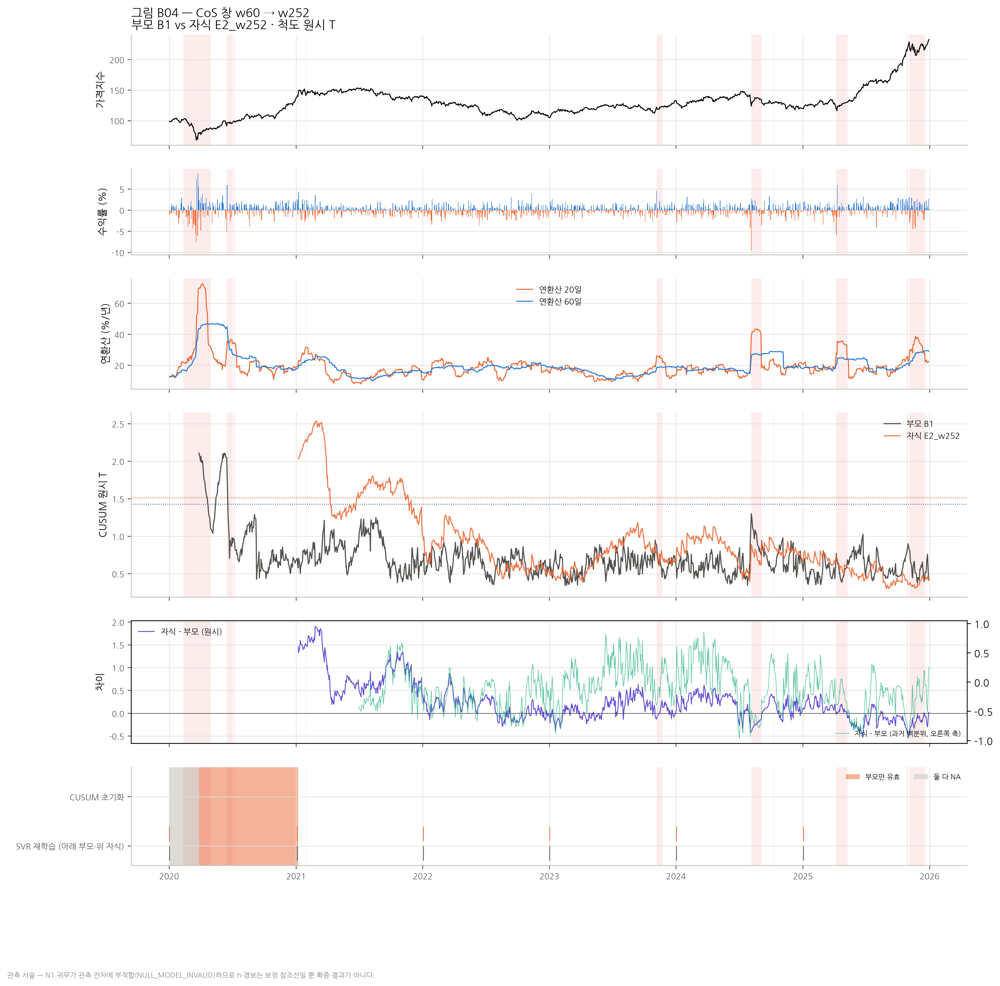

In [15]:
display(Image(data=preview(FIGDIR / "G05_04_부모자식_B1_vs_E2_w252.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

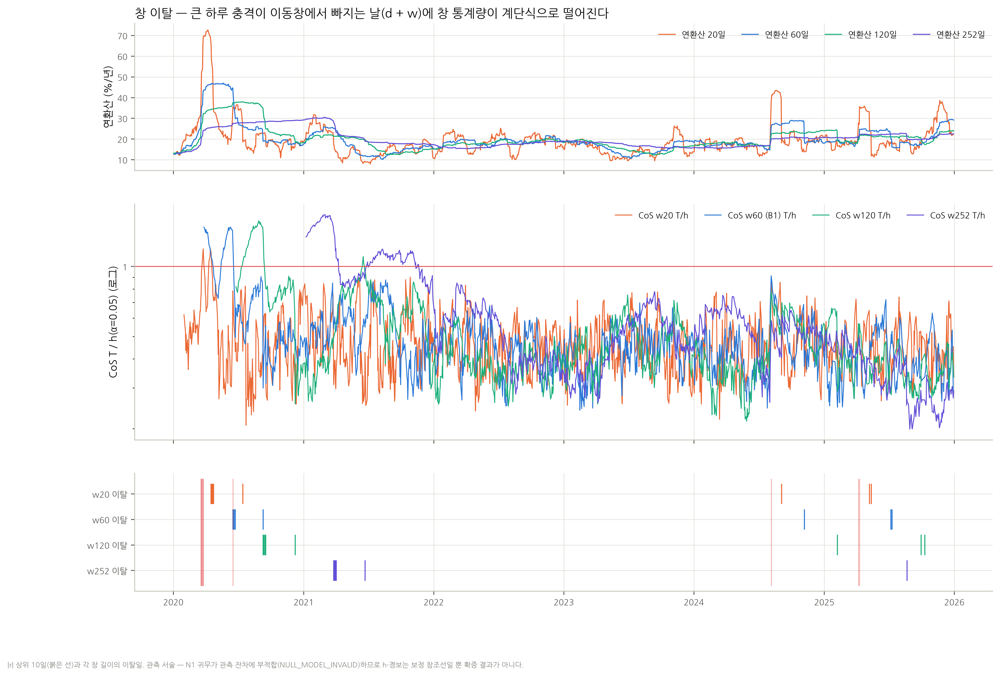

In [16]:
display(Image(data=preview(FIGDIR / "G07_창이탈_효과.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

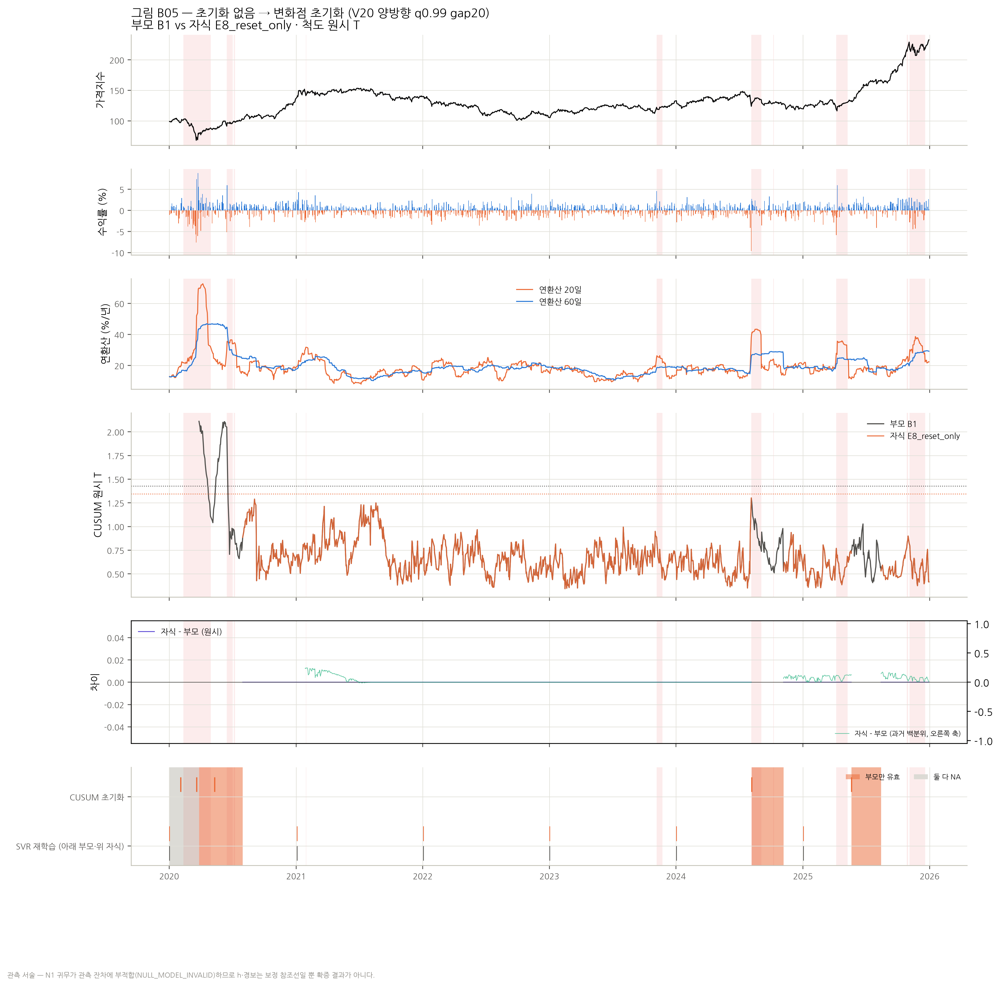

In [17]:
display(Image(data=preview(FIGDIR / "G05_05_부모자식_B1_vs_E8_reset_only.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

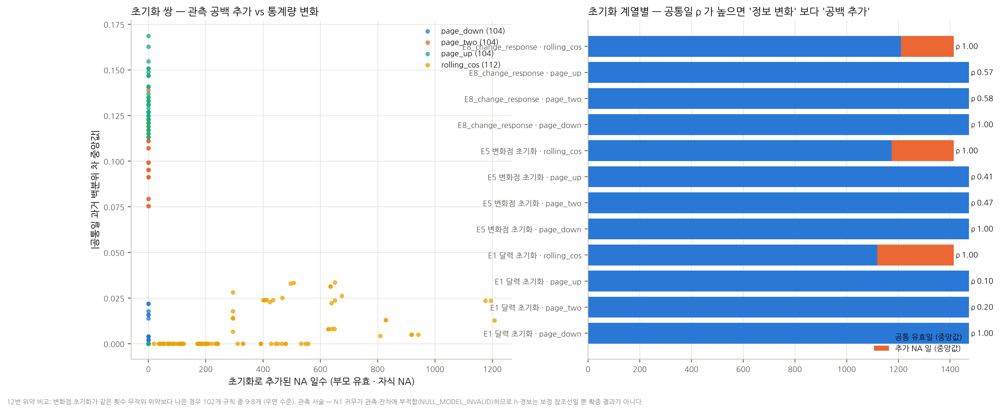

In [18]:
display(Image(data=preview(FIGDIR / "G13_초기화_관측공백.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

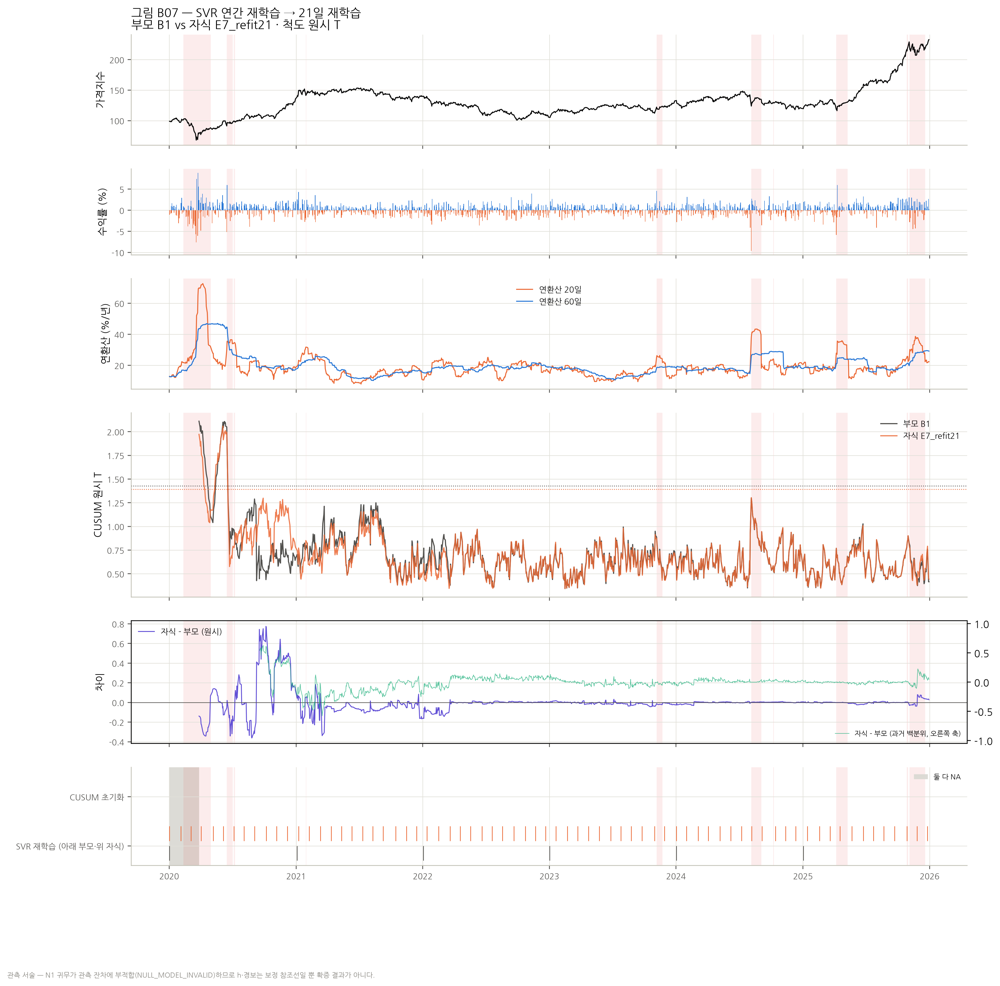

In [19]:
display(Image(data=preview(FIGDIR / "G05_07_부모자식_B1_vs_E7_refit21.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

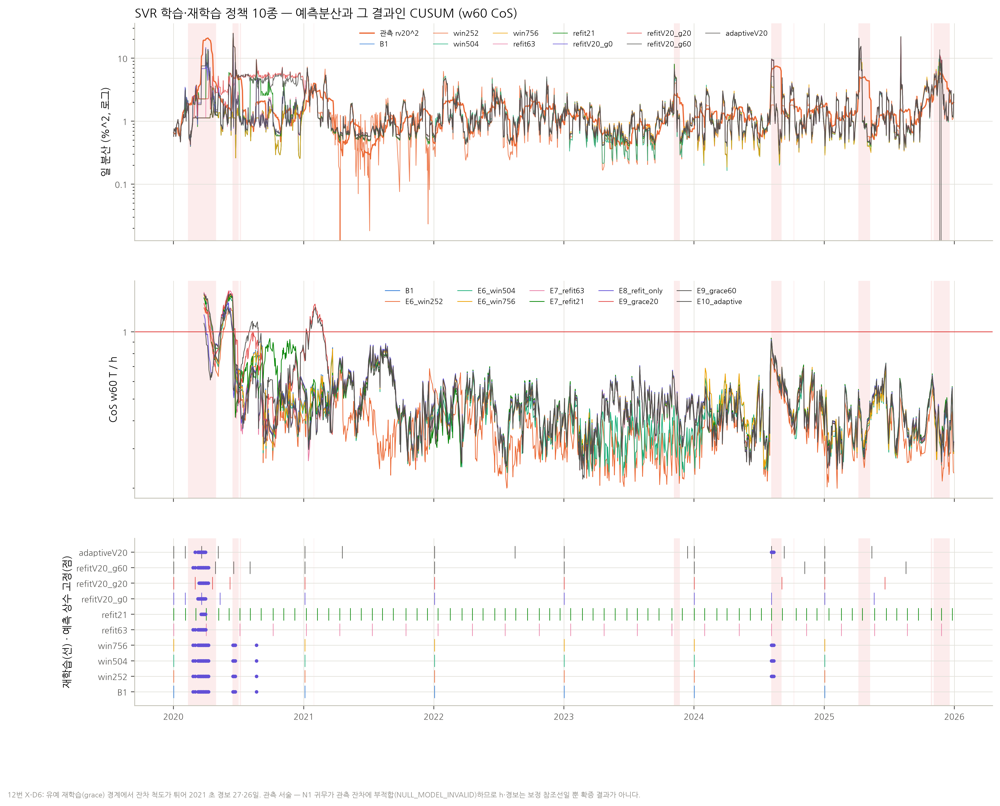

In [20]:
display(Image(data=preview(FIGDIR / "G14_SVR정책_비교.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

In [21]:
# 대표 부모–자식 쌍 지표
display(T['ofat_pair_comparison.csv'].set_index('child').loc[['B0','E2_w20','E2_w120','E2_w252','E8_reset_only','E6_win252','E7_refit21','X1_page_up_sn','X1_page_down_sn','E3_raw_rolling_cos'],['parent','changed_variable','common_valid_days','parent_only_days','child_only_days','raw_spearman','pct_diff_mean_expanding','pct_diff_mean_contracting','alarm_days_parent','alarm_days_child','added_na_days']].round(3))  # 표 출력

,parent,changed_variable,common_valid_days,parent_only_days,child_only_days,raw_spearman,pct_diff_mean_expanding,pct_diff_mean_contracting,alarm_days_parent,alarm_days_child,added_na_days
child,,,,,,,,,,,
B0,B1,reset,1119,295,0,1.000,-0.036,-0.039,43,45,295
E2_w20,B1,w,1414,0,40,0.072,-0.110,-0.061,43,10,0
E2_w120,B1,w,1354,60,0,0.382,-0.138,-0.079,43,48,60
E2_w252,B1,w,1222,192,0,0.351,-0.292,-0.233,43,159,192
E8_reset_only,B1,reset,1210,204,0,1.000,0.037,0.039,43,0,204
E6_win252,B1,svr,1414,0,0,0.668,-0.087,-0.008,43,33,0
E7_refit21,B1,svr,1414,0,0,0.891,-0.036,-0.024,43,39,0
X1_page_up_sn,E3_page_up,detector,1293,180,0,-0.247,0.172,0.134,2,0,180
X1_page_down_sn,E3_page_down,detector,1293,180,0,0.499,-0.048,0.008,1,4,180


## 6. 연환산변동성 국면 · 사건 · 시차

국면은 계산 전에 고정한 과거 전용 정의다 (연환산 20일: 수준 4 × 변화 3). 흐린 칸은 유효일 20 미만이라 해석하지 않는다.
- **확대**: 이동 CoS 가 가장 크게 오른다 (원수익률 CoS +0.27, B1 +0.19).
- **높은 수준 유지**: Page 상방만 높다 (+0.25) — 표류가 섞인 반응이다. SVR 잔차 CoS 는 무반응 (B1 +0.001).
- **감소**: CoS(+0.13), Page 하방, X1 하방.
- **시차**: Page·X1 은 같은 날 반응이 가장 강하다 (Page 상방 +0.44, 하방 −0.46). CoS w60 의 k = −19 최대는 20일 앵커의 창 이탈 메아리다.

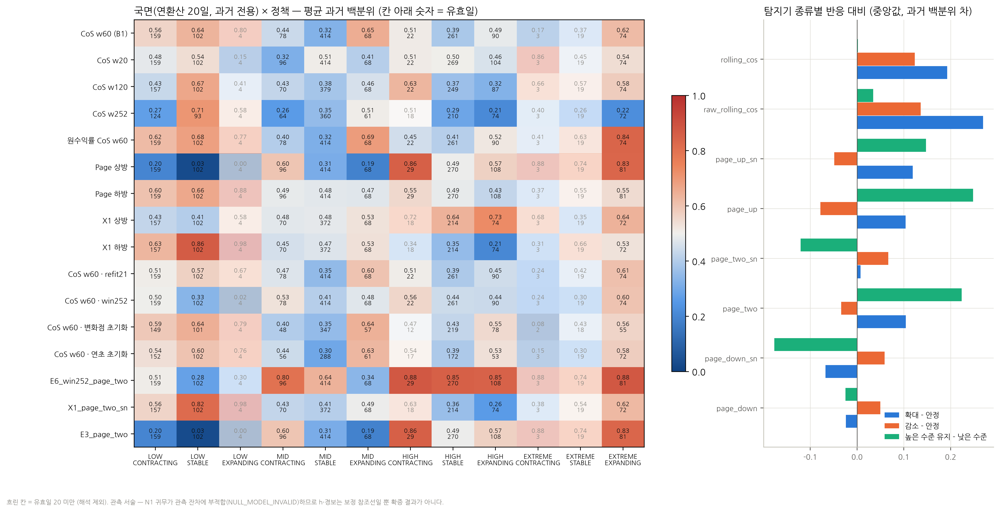

In [22]:
display(Image(data=preview(FIGDIR / "G08_국면별_정책반응.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

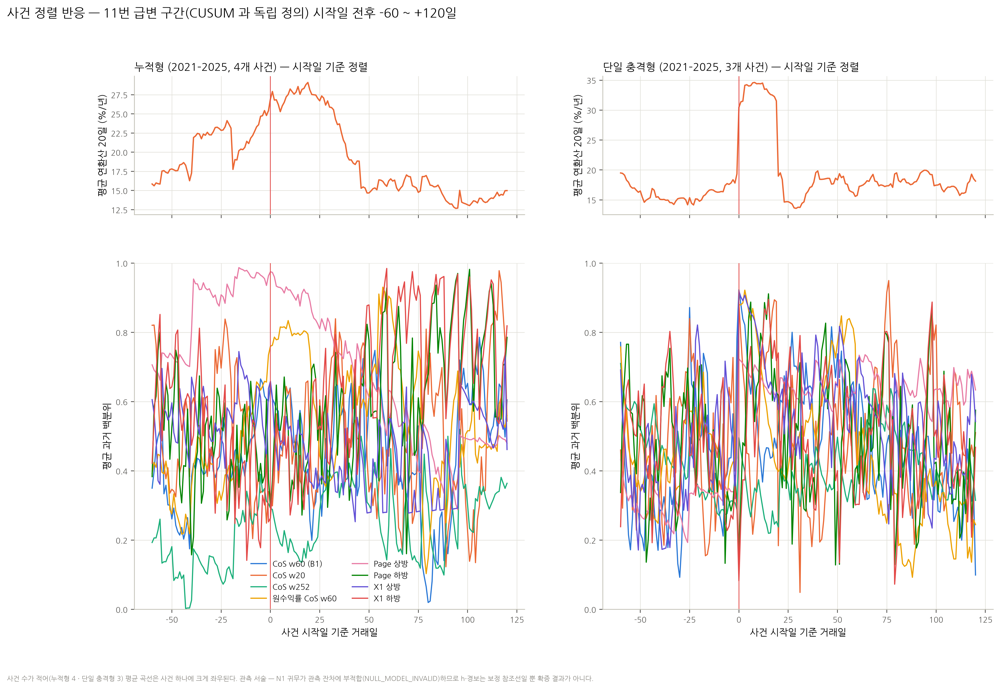

In [23]:
display(Image(data=preview(FIGDIR / "G09_사건정렬_반응.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

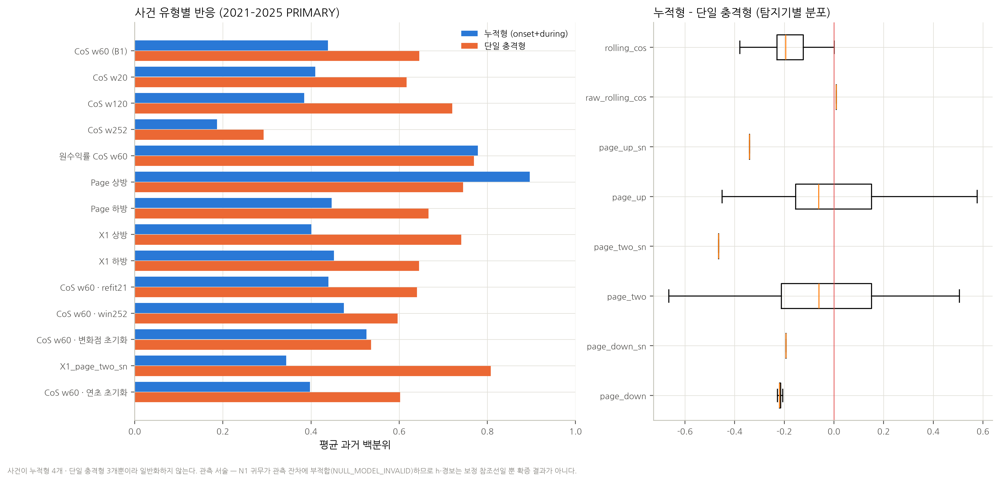

In [24]:
display(Image(data=preview(FIGDIR / "G15_단일vs누적_충격.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

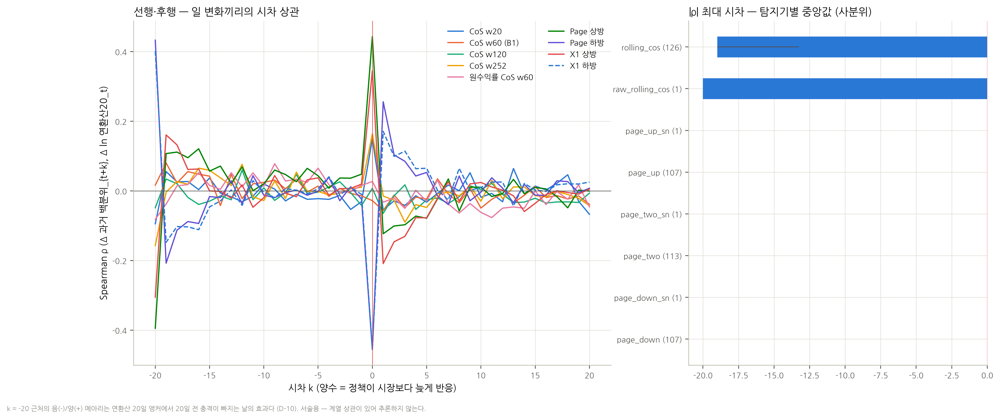

In [25]:
display(Image(data=preview(FIGDIR / "G10_선행후행.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

In [26]:
# 대표 정책의 국면 반응 (2020 제외 포함)
display(T['annualized_volatility_response.csv'].set_index('experiment_id').loc[['B1','E2_w20','E2_w252','E3_raw_rolling_cos','E3_page_up','E3_page_down','X1_page_up_sn','X1_page_down_sn','X1_page_two_sn'],['rho_vol20','rho_vol20_ex2020','rho_d5','contrast_EXPANDING_minus_STABLE','contrast_CONTRACTING_minus_STABLE','contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE']].round(3))  # 표 출력

,rho_vol20,rho_vol20_ex2020,rho_d5,contrast_EXPANDING_minus_STABLE,contrast_CONTRACTING_minus_STABLE,contrast_HIGHEXT_STABLE_minus_LOWMID_STABLE
experiment_id,,,,,,
B1,-0.130,-0.132,0.085,0.194,0.130,0.001
E2_w20,0.020,0.013,0.040,-0.042,-0.075,-0.014
E2_w252,-0.189,-0.189,0.050,-0.071,-0.089,-0.135
E3_raw_rolling_cos,-0.050,-0.050,0.130,0.270,0.136,0.035
E3_page_up,0.578,0.602,0.153,0.195,0.057,0.254
E3_page_down,-0.106,-0.118,-0.259,-0.024,0.050,-0.025
X1_page_up_sn,0.262,0.262,0.312,0.119,-0.049,0.147
X1_page_down_sn,-0.376,-0.376,-0.235,-0.068,0.059,-0.177
X1_page_two_sn,-0.271,-0.271,-0.081,0.008,0.067,-0.121


## 7. 463개 정책은 몇 개의 신호인가

공통 유효일 원시 T 의 Spearman ρ ≥ 0.9 로 묶으면 값 군집 73개 (단일 29개). 가장 큰 117개 군집(B1·B0·변화점 초기화 CoS 대부분)과 107개 Page 하방 군집은 사실상 한 신호다.
CoS 창 w20·w30·w120·w252, 원수익률 CoS, SVR 학습창 정책, X1 3종은 서로 독립된 시간 규모다. 결측 패턴은 값과 따로 군집화했다.

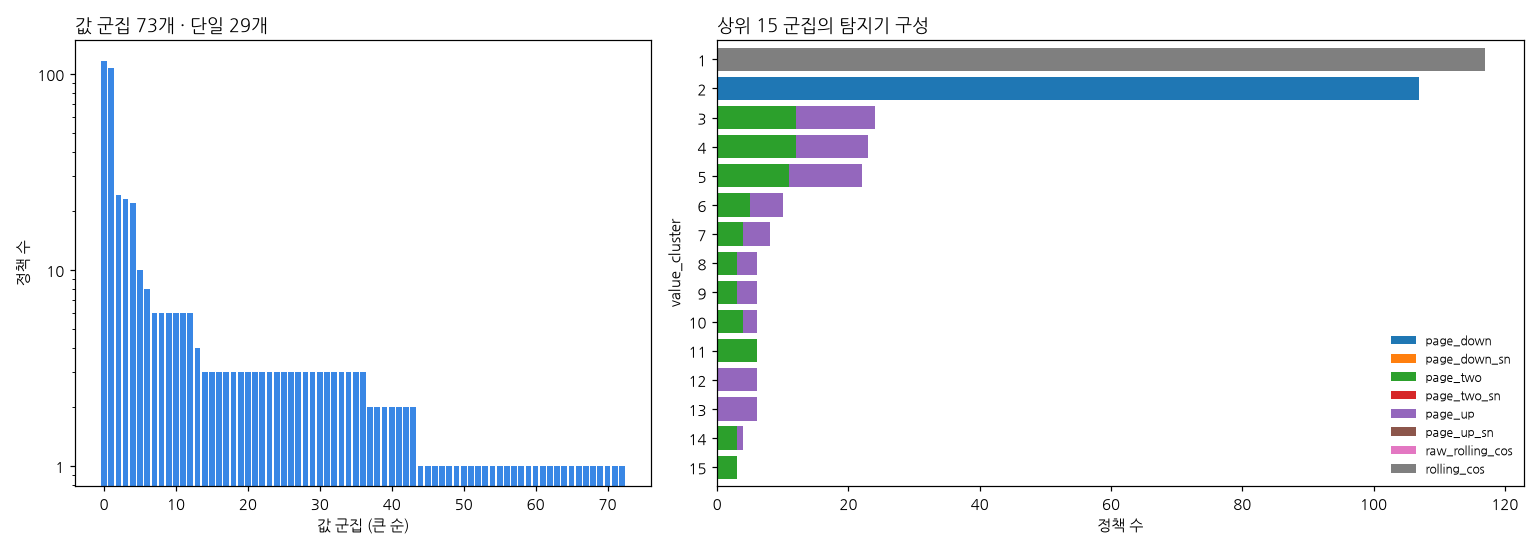

In [27]:
# 실시간 그림: 463 정책이 몇 개의 신호로 묶이는가 — 값 군집 크기 분포와 탐지기 구성 (agreement_clusters.csv)
cl = T["agreement_clusters.csv"]  # 정책별 값 군집
sz = cl.groupby("value_cluster").size().sort_values(ascending=False)  # 군집 크기
comp = cl.groupby(["value_cluster", "detector_type"]).size().unstack(fill_value=0).loc[sz.index[:15]]  # 상위 15 군집 구성
fig_, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.4]})  # 두 패널
ax[0].bar(range(len(sz)), sz.values, color="#3987e5")  # 군집 크기 막대
ax[0].set_yscale("log")  # 크기 차이가 커서 로그
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))  # 일반 숫자 눈금
ax[0].set_xlabel("값 군집 (큰 순)")  # 축 이름
ax[0].set_ylabel("정책 수")  # 축 이름
ax[0].set_title(f"값 군집 {len(sz)}개 · 단일 {int((sz == 1).sum())}개", loc="left")  # 제목
comp.plot.barh(stacked=True, ax=ax[1], width=0.8)  # 구성 누적 막대
ax[1].invert_yaxis()  # 큰 군집이 위로
ax[1].set_xlabel("정책 수")  # 축 이름
ax[1].set_title("상위 15 군집의 탐지기 구성", loc="left")  # 제목
ax[1].legend(fontsize=8, frameon=False)  # 범례
plt.tight_layout()  # 여백 정리
buf = io.BytesIO()  # 그림 버퍼
fig_.savefig(buf, format="png", dpi=110)  # 노트북용 해상도
plt.close(fig_)  # 메모리 해제
display(Image(data=buf.getvalue()))  # 표시

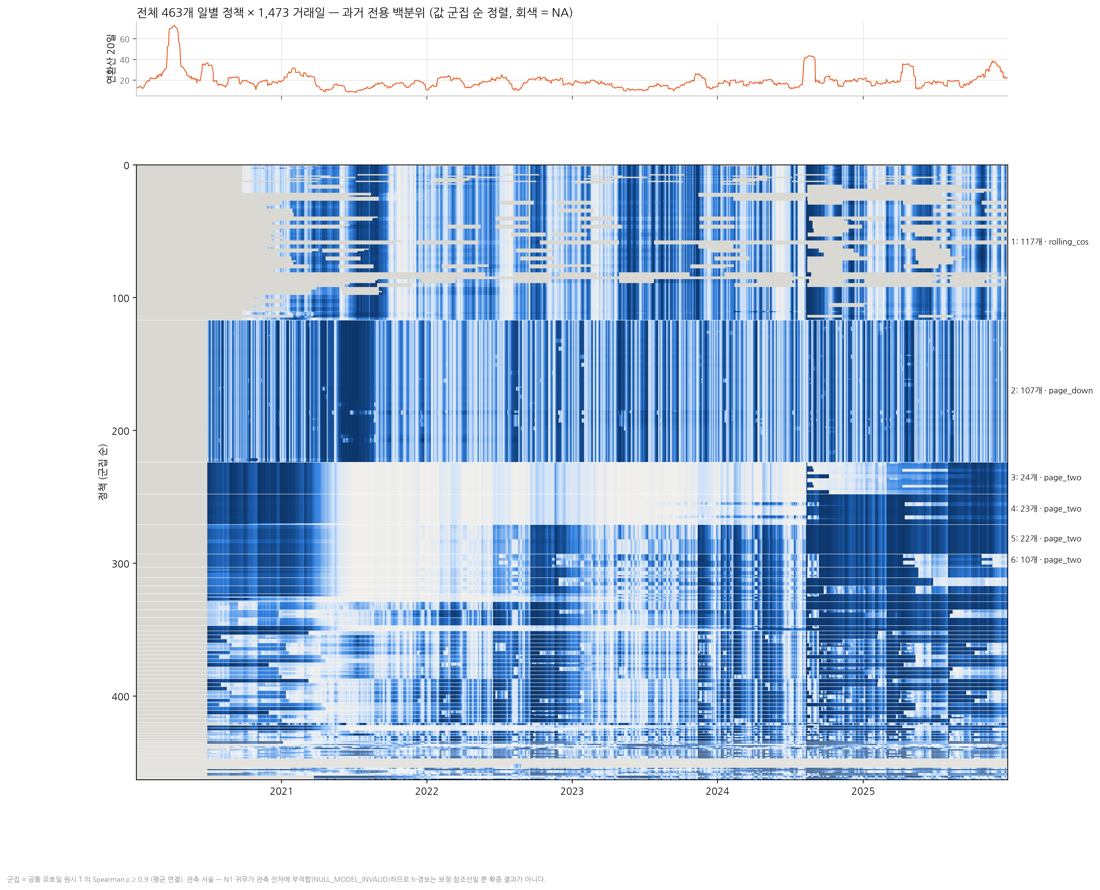

In [28]:
display(Image(data=preview(FIGDIR / "G11_전체정책_히트맵.png", width=1100)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

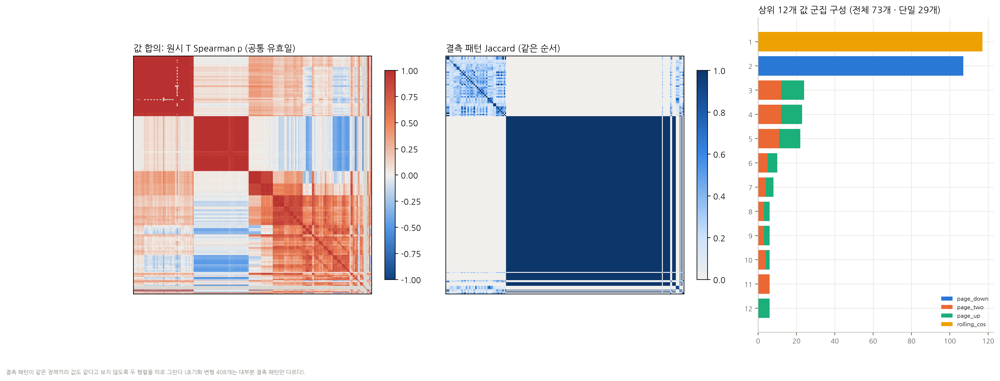

In [29]:
display(Image(data=preview(FIGDIR / "G12_정책합의_중복성.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

## 8. Autoencoder 에 넘길 피처

미래 20일 실현변동성 예측에서, 관측·예측 변동성만 쓴 기준보다 상대 MSE 가 얼마나 줄었는지 쟀다 (한 해씩 빼고 시험, 표본외지만 실시간 예측은 아님). 정책마다 유효일이 달라 공통 846일에서도 따로 비교했다.
- Page 하방 계열 +3.5% (시험연도 5개 중 4개 개선, 공통일 비교 5개 모두) · X1 양방향 +8.1% (공통일 +2.7%) · CoS w120·w252 +2.4%·+3.9%
- CoS w60 계열 −1.7% — 원시 변동성에 이미 담긴 정보다.

| 넘길 것 | 시간 규모 | 근거 |
|---|---|---|
| SVR 잔차 이동 CoS (창마다 1개) | 20 · 60 · 120 · 252일 | 창마다 다른 값 군집 |
| 원수익률 CoS | 60일 | SVR 비의존 기준, 확대 반응 최대 |
| Page 하방 (대표 1개) | 누적 | +3.5%, 변형 107개는 중복 |
| X1 하방 · 양방향 | 누적 | 탐색 — 2026 이후 자료로 검증 후 |
| SVR 예측분산 + 상수 고정 표시 | 1일 | 고정일 잔차 ≈ 원수익률 |
| 마스크 (초기화·재학습 경과일, 창 이탈일) | — | 공백·창 잔존·경계 식별 |

넘기지 않는 것: Page 상방 원시 상태(표류, 공통일 −8.6%), CoS 초기화 변형, 경보·p값, 사후 백분위.

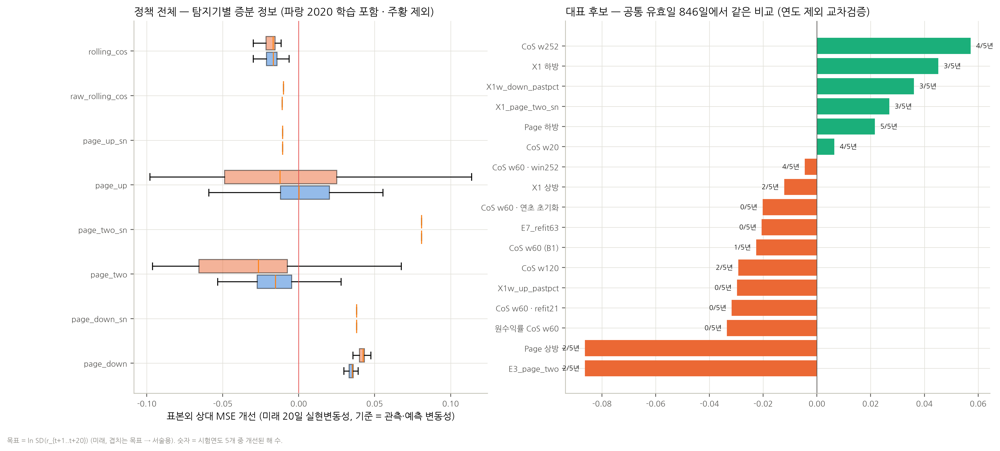

In [30]:
display(Image(data=preview(FIGDIR / "G16_AE피처_증분정보.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

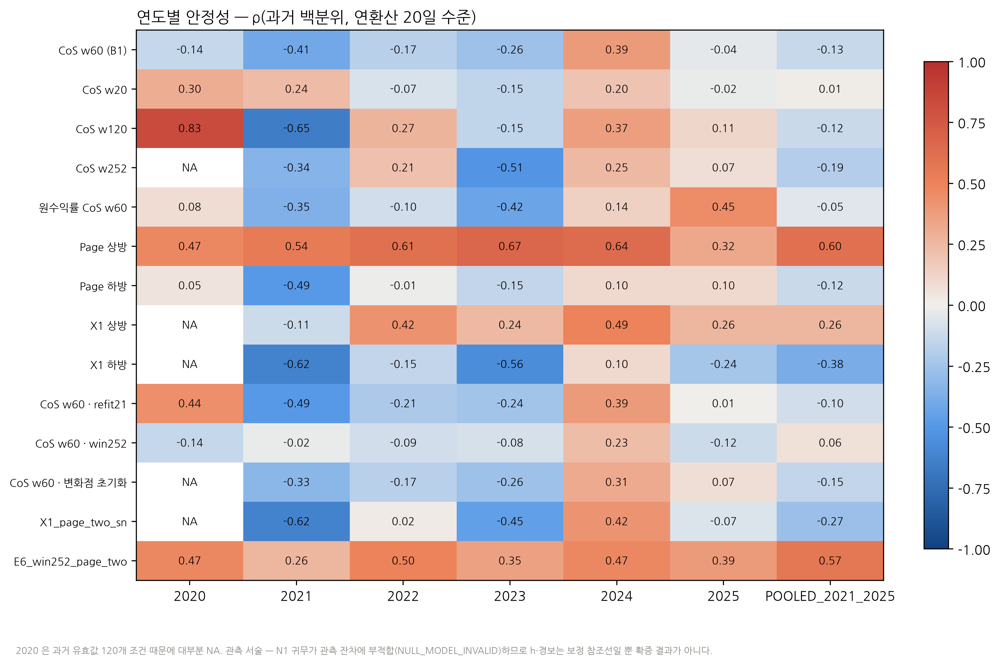

In [31]:
display(Image(data=preview(FIGDIR / "G17_연도별_안정성.png", width=1000)))  # 저장된 PNG(320dpi)의 축소 미리보기 (원본은 figures/)

In [32]:
# 공통 유효일 846일에서 대표 후보 비교
display(T['feature_incremental_information_common_days.csv'].query('~exclude_2020_train')[['feature','n_common','rel_mse_gain_pooled','years_positive','gain_2021','gain_2022','gain_2023','gain_2024','gain_2025']].sort_values('rel_mse_gain_pooled', ascending=False).round(4))  # 표 출력

,feature,n_common,rel_mse_gain_pooled,years_positive,gain_2021,gain_2022,gain_2023,gain_2024,gain_2025
6,E2_w252,846,0.0572,4,-1.0867,0.0593,0.3030,0.0859,0.1161
18,X1_page_down_sn,846,0.0452,3,0.1787,-0.0720,0.1924,-0.0039,0.0635
32,X1w_down_pastpct,846,0.0361,3,0.2006,-0.0927,0.1727,-0.0098,0.0470
20,X1_page_two_sn,846,0.0270,3,0.0994,-0.2126,0.3167,-0.2203,0.1990
12,E3_page_down,846,0.0216,5,0.0021,0.0203,0.0200,0.0244,0.0505
2,E2_w20,846,0.0065,4,0.0937,0.0135,0.0325,-0.0261,0.0116
28,E6_win252,846,-0.0045,4,0.0168,0.0346,-0.0828,0.0125,0.0123
16,X1_page_up_sn,846,-0.0122,2,0.1528,-0.0390,-0.1096,-0.0115,0.0295
8,B0,846,-0.0202,0,-0.0539,-0.0530,-0.0740,-0.0024,-0.0024
26,E7_refit63,846,-0.0206,0,-0.0887,-0.0572,-0.0570,-0.0086,-0.0021


## 9. 연구 질문 10개에 대한 답

1. **급증에 가장 강하게 반응** — 이동 CoS (원수익률 +0.27, SVR 잔차 +0.19). 같은 날 반응은 Page 상방·하방.
2. **높은 수준 유지** — Page 상방 (+0.25, 수준 ρ 0.58). 표류가 섞였고 X1 은 0.26. CoS 는 무반응.
3. **감소** — CoS (+0.13), Page 하방 (5일 변화율과 ρ −0.26), X1 하방.
4. **창 길이만 바꾸면** — 날짜별 순위가 바뀌고(w20–w60 ρ 0.07), 긴 창은 충격을 창 이탈일까지 기억한다.
5. **변화점 초기화** — CoS 에서는 관측 공백 추가가 대부분 (NA 중앙값 242일, 값 ρ ≈ 1). 무작위 초기화보다 나은 경우는 우연 수준.
6. **SVR 때문에 생긴 인위적 반응 날짜** — 예측분산 상수 고정 2020-02-25 ~ 08-21 · 2024-08-06 ~ 12, 재적합 경계 척도 단절 2020-04-02(refit63)·2022-01-03(B1), 2021 초 유예 재학습 경계.
7. **2020 제외** — 수준 상관 부호가 바뀐 정책 0개. 과거 전용 척도는 2020 대부분이 NA 라 근거가 약하다.
8. **원시 변동성 밖의 정보** — Page 하방, X1 하방·양방향, 긴 창(w120·w252).
9. **유사 정책군 / 독립 시간 규모** — 117개 CoS 군집, 107개 Page 하방 군집은 중복. 창 길이·공식·SVR 학습창·X1 은 독립.
10. **AE 인계** — 8절 표. 경보는 넘기지 않는다.

## 10. 한계와 다음 단계

- 사건 7개, 시험연도 5개, 예측 목표 구간이 겹친다. 과거 전용 척도는 2020 대부분이 NA. X1w 는 임계값 미보정.
- 다음 단계 제안: 고정일 v^ 를 바꿔 넣는 반사실 계산으로 2020 경보 중 상수 고정 몫을 분리 · X1 을 다른 ETF·2026 맹검으로 사전 등록 검증 · AE 입력을 8절 대표 정책으로 축소.

상호작용 탐색기: `research/k200_cusum_overlay_12b/interactive/12B_시장_CUSUM_탐색기.html` · 전체 그림 27장: `research/k200_cusum_overlay_12b/figures/`

## 11. 수치 대조 · 보호 확인

In [33]:
# 본문 수치를 결과 파일에서 다시 계산해 대조한다 (연구 노트북과 같은 notebook_claims.json).
CL = json.loads((BASE / "notebook_claims.json").read_text(encoding="utf-8"))  # (주장, 결과파일, 식, 기대값)
bad = {}  # 불일치 주장
for c in CL:  # 주장마다
    df = pd.read_csv(RES / c["file"])  # 근거 결과표
    got = eval(c["expr"], {"df": df, "np": np, "pd": pd})  # 결과표에서 다시 계산한 값
    got = round(float(got), c["round"]) if isinstance(got, (int, float, np.floating, np.integer, bool)) else got  # 반올림 규칙
    exp = round(float(c["expected"]), c["round"]) if isinstance(c["expected"], (int, float)) else c["expected"]  # 기대값
    if got != exp:  # 다르면
        bad[c["claim"]] = (got, exp)  # 기록
print(f"CLAIMS {len(CL) - len(bad)}/{len(CL)} 일치")  # 결과
assert not bad, bad  # 불일치면 실패
bad_p = [p for h, p in PROT if sha(ROOT / p) != h]  # 12번 보호 파일 재확인
assert not bad_p, bad_p  # 변경 금지
print("12번 보호", len(PROT), "개 불변 · 그림", len(list(FIGDIR.glob("*.png"))), "장 · 결과표", len(T), "개")  # 요약

CLAIMS 73/73 일치
12번 보호 915 개 불변 · 그림 27 장 · 결과표 25 개
